In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split

1) Data Loading and Business Understanding

In [74]:
columns = [
    'status_checking', 'duration_months', 'credit_history', 'purpose',
    'credit_amount', 'savings', 'employment_since', 'installment_rate',
    'personal_status_sex', 'other_debtors', 'residence_since', 'property',
    'age', 'other_installment_plans', 'housing', 'existing_credits',
    'job', 'people_liable', 'telephone', 'foreign_worker', 'target'
]

df = pd.read_csv('german.data', sep=r"\s+", header=None, names=columns)

In [75]:
print(df.shape)
df['target'].value_counts()

(1000, 21)


target
1    700
2    300
Name: count, dtype: int64

In [76]:
df.head()

,status_checking,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


What is a “default / bad risk” in a bank context?

Default mean a borrower fails to repay a loan or misses payments as agreed
Bad risk customer is one the bank considerd likely to default (target = 2 in the dataset)

Why mistakes matter (false negatives vs false positives)

In this task, the positive class is 'bad', since that is what the bank wants to detect

False negative (bad customer predicted as good) means the bank gives a loan that may not be repaid, causing a direct financial loss.

False positive (good customer predited as bad) means the bank rejects a reliable client and loses potential profit form interest. 

According to the dataset's cost matrix, a false negative costs 5 times more than a false positive. therefore, the model should prioritize catching bad customers (high recall for the bad class), not just maximize accuracy.

2) Data Quality and Simple EDA

Task 2.1 Missing values & data types

Check missing values

In [77]:
df.isnull().sum()

status_checking            0
duration_months            0
credit_history             0
purpose                    0
credit_amount              0
savings                    0
employment_since           0
installment_rate           0
personal_status_sex        0
other_debtors              0
residence_since            0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
people_liable              0
telephone                  0
foreign_worker             0
target                     0
dtype: int64

Identify numeric vs categorical features

In [78]:
X = df.drop(columns='target')   

numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()

print('Numeric:', numeric_features, len(numeric_features))
print('\nCategorical:', categorical_features, len(categorical_features))

Numeric: ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'people_liable'] 7

Categorical: ['status_checking', 'credit_history', 'purpose', 'savings', 'employment_since', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker'] 13


Task 2.2 Correlation

Compute correlation matrix for numeric columns

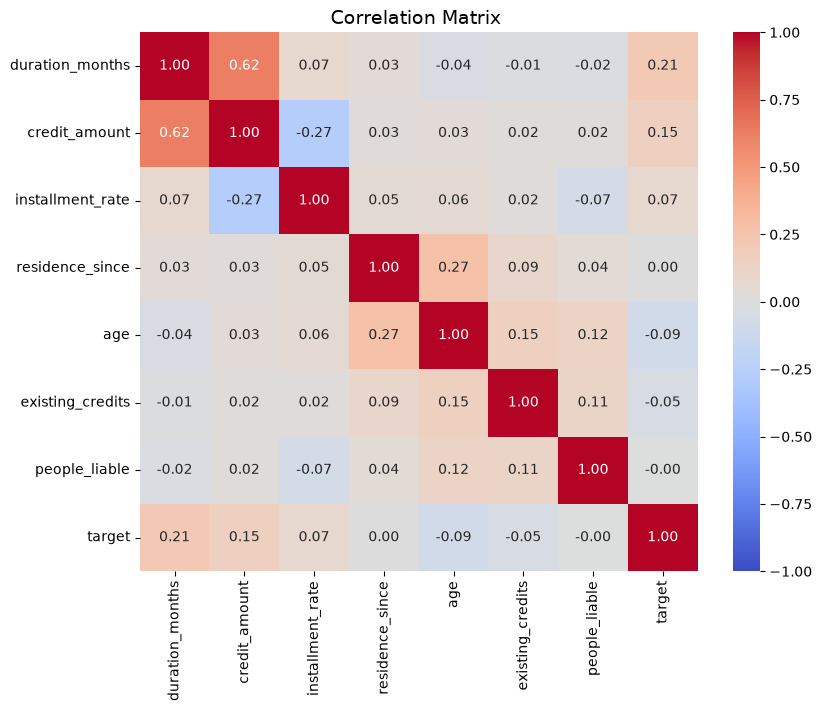

In [79]:
grad_numeric = df.select_dtypes(include='number')
plt.figure(figsize=(9,7))
sns.heatmap(grad_numeric.corr(), annot = True, cmap = 'coolwarm', fmt = '.2f', vmin = -1, vmax = 1)
plt.title('Correlation Matrix ', fontsize = 14)
plt.show()

Pick Top-3 numeric features most correlated with the target

In [80]:
corr_target = grad_numeric.corr()['target'].drop('target')
top3 = corr_target.abs().sort_values(ascending=False).head(3).index

corr_target[top3].round(3)

duration_months    0.215
credit_amount      0.155
age               -0.091
Name: target, dtype: float64

duration_months(0.21): longer loans are risker; the longer the repayment period, the more time for the borrower's situation to change (job loss, other expenses), so the chance of default increases. 

credit_amount (0.15): larger loans are harder to repay, so customers with bigger credit amounts are slightly more likely to be bad risk. It is also strongly correlated with duration (0.62), so these two features partly carry the same information.

age (−0.09): the negative sign means older customers tend to be slightly more reliable, likely due to more stable income and financial experience.

3) Preprocessing

Task 3.1 Split train/test

Split into train/test (e.g., 80/20)

Use random_state for reproducibility

In [81]:
X = df.drop(columns = 'target')
y = (df['target'] == 2).astype(int)   # 1 = bad, 0 = good

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size = 0.2, 
    random_state = 42,
     stratify = y
)
print(X_train.shape, X_test.shape)

(800, 20) (200, 20)


In [82]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

target
0    0.7
1    0.3
Name: proportion, dtype: float64
target
0    0.7
1    0.3
Name: proportion, dtype: float64


Task 3.2 Prepare pipeline

Categorical → OneHotEncode

Numeric → StandardScaler (if required)

In [83]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(include='number').columns.tolist()
categorical_features = X_train.select_dtypes(exclude='number').columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

4) Build 3 Baseline Models (No Tuning)

Task 4.1 Train models

Fit each model using the same preprocessing pipeline.
Train exactly these 3 models:
1. Logistic Regression
2. Decision Tree
3. kNN

In [84]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'kNN': KNeighborsClassifier()
}

pipelines = {}
for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe

Task 4.2 Evaluate models

For each model, compute:

Accuracy

Confusion Matrix

Precision, Recall, F1

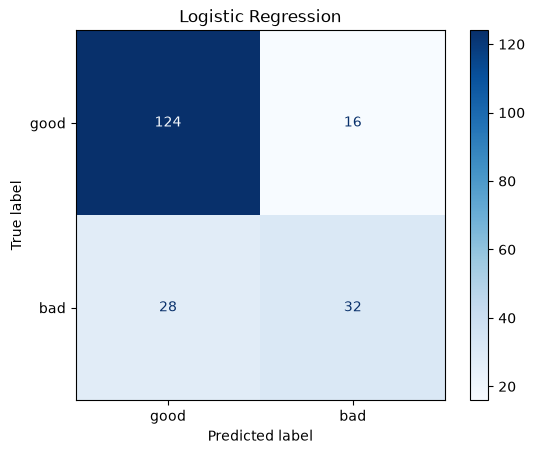

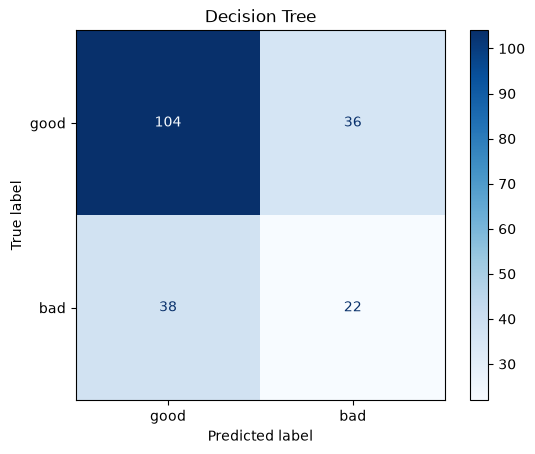

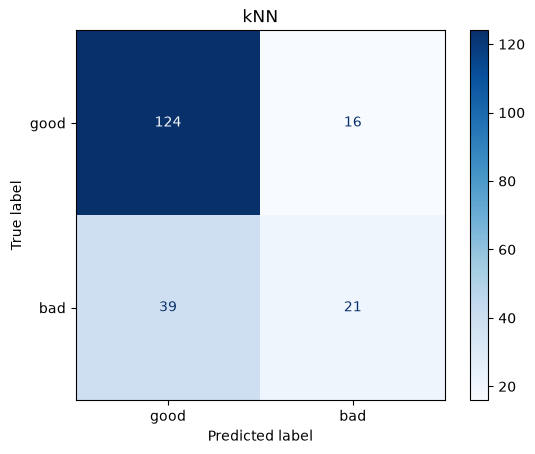

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.780,0.667,0.533,0.593
1,Decision Tree,0.630,0.379,0.367,0.373
2,kNN,0.725,0.568,0.350,0.433


In [85]:
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)

results = []

for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred)
    })

    # confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['good', 'bad']).plot(cmap='Blues')
    plt.title(name)
    plt.show()

results_df = pd.DataFrame(results).round(3)
results_df

In credit risk, which is worse: approving a bad client (FN) or rejecting a good one (FP)? Explain.

In credit risk, a false negative (approving a bad client) is worse than a false positive (rejecting a good client).
A false negative means the bank gives money that will likely not be returned- a direct financial loss of the loan amount.
A false positive only means the bank loses potential profit from interest and possibly an unhappy customer.
This is confirmed by the dataset's cost matrix: a false negative costs 5, while a false positive costs 1.
Therefore, recall for the bad class is more important than accuracy when comparing models.

5) Simple “Business Threshold”
Logistic regression outputs probabilities

Compare 3 thresholds
Compute confusion matrix and metrics (f1, recall, precision) for for test set:

Threshold = 0.65

Threshold = 0.50

Threshold = 0.35

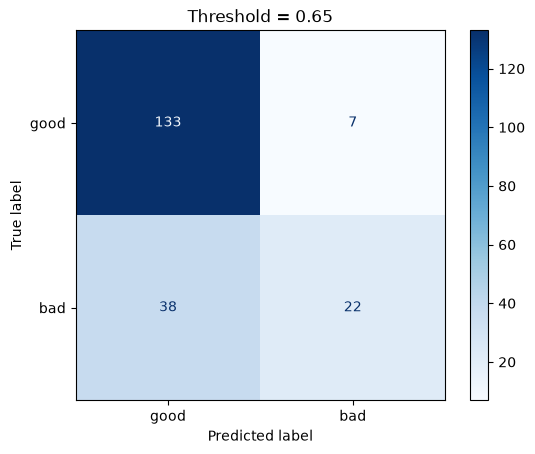

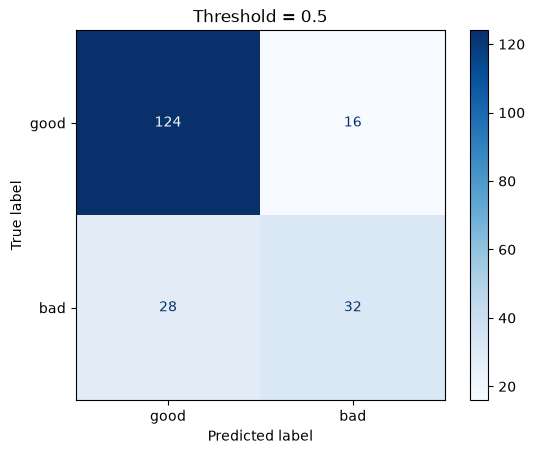

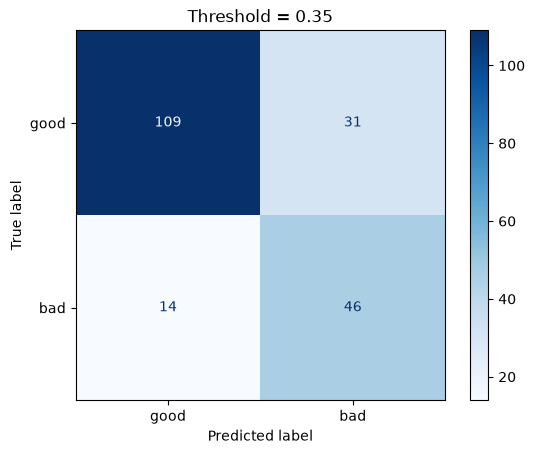

,Threshold,Precision,Recall,F1,Rejected clients,Bad approved (FN),Good rejected (FP),Cost (5*FN + 1*FP)
0,0.65,0.759,0.367,0.494,29,38,7,197
1,0.50,0.667,0.533,0.593,48,28,16,156
2,0.35,0.597,0.767,0.672,77,14,31,101


In [86]:
log_reg = pipelines['Logistic Regression']
y_proba = log_reg.predict_proba(X_test)[:, 1]

thresholds = [0.65, 0.50, 0.35]
results = []

for t in thresholds:
    y_pred = (y_proba >= t).astype(int)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    results.append({
        'Threshold': t,
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'Rejected clients': fp + tp,           
        'Bad approved (FN)': fn,
        'Good rejected (FP)': fp,
        'Cost (5*FN + 1*FP)': 5 * fn + fp      
    })

    ConfusionMatrixDisplay(cm, display_labels=['good', 'bad']).plot(cmap='Blues')
    plt.title(f'Threshold = {t}')
    plt.show()

threshold_df = pd.DataFrame(results).round(3)
threshold_df

Explain:

Which threshold you recommend and why

How does lowering the threshold change the number of rejected clients?

Which threshold reduces the number of bad clients approved?

Which threshold increases the number of good clients rejected?

If you were the Head of Risk, which threshold would you recommend and why?

I recommend threshold = 0.35. It has the lowest total cost (101, compared to 156 at 0.50 and 197 at 0.65), the highest recall for bad clients (0.767), and also the highest F1-score (0.672). It catches 46 out of 60 bad clients, while the default threshold of 0.50 catches only 32.

Lowering the threshold makes the model stricter, because a client is rejected even at a lower predicted probability of default. The number of rejected clients grows from 29 (0.65) to 48 (0.50) and to 77 (0.35), meaning the rejection rate increases from about 15% to almost 39% of applicants.

Threshold 0.35. The number of bad clients who receive a loan (false negatives) drops from 38 at 0.65 to 28 at 0.50 and only 14 at 0.35, almost three times fewer than at 0.65.

Also threshold 0.35. False positives rise from 7 at 0.65 to 16 at 0.50 and 31 at 0.35, so about 22% of good clients (31 out of 140) are wrongly rejected. This is why precision decreases from 0.759 to 0.597: the model becomes stricter but makes more mistakes with reliable customers.

As Head of Risk, I would choose 0.35. According to the cost matrix, approving a bad client costs 5 times more than rejecting a good one, and at 0.35 the total cost is almost half of the cost at 0.65 (101 vs 197). Losing interest income from 31 good clients is cheaper than losing the loan amount from 24 additional defaulters. However, a 39% rejection rate is quite high, so the bank should monitor whether this hurts its customer base, and it could test thresholds between 0.35 and 0.50 to find a better balance.

6) Production-Oriented task: “Manual Review Queue”
In real banks, not all decisions are automatic.

Task 6.1 Create 3 decision zones using probability
Using logistic regression probability p:

Auto-approve: p < 0.20

Manual review: 0.20 ≤ p ≤ 0.50

Auto-reject: p > 0.50

Deliverables:

Count how many applications fall in each zone
Business interpretation: how this reduces workload and risk

In [87]:
zones = np.select(
    [y_proba < 0.20, y_proba <= 0.50],
    ['Auto-approve', 'Manual review'],
    default='Auto-reject'
)

zone_df = pd.DataFrame({
    'probability': y_proba,
    'zone': zones,
    'actual': y_test.values    # 1 = bad, 0 = good
})

summary = zone_df.groupby('zone').agg(
    applications=('actual', 'size'),
    bad_clients=('actual', 'sum')
).reindex(['Auto-approve', 'Manual review', 'Auto-reject'])

summary['share_%'] = (summary['applications'] / len(zone_df) * 100).round(1)
summary['bad_rate_%'] = (summary['bad_clients'] / summary['applications'] * 100).round(1)
summary

,applications,bad_clients,share_%,bad_rate_%
zone,,,,
Auto-approve,91,10,45.5,11.0
Manual review,61,18,30.5,29.5
Auto-reject,48,32,24.0,66.7


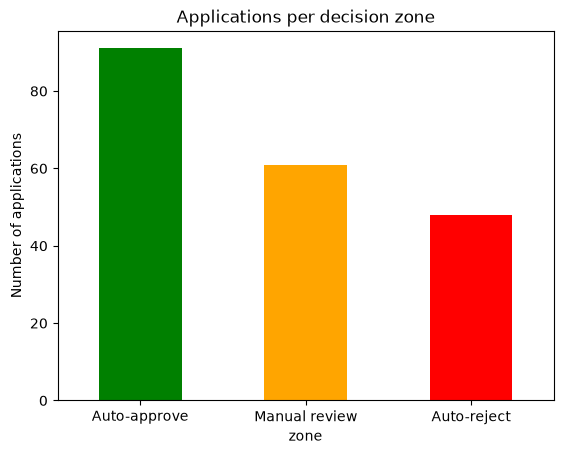

In [88]:
summary['applications'].plot(kind='bar', color=['green', 'orange', 'red'])
plt.title('Applications per decision zone')
plt.ylabel('Number of applications')
plt.xticks(rotation=0)
plt.show()

Applications per zone (test set, 200 applications):
- Auto-approve (p < 0.20): 91 applications (45.5%), bad rate 11.0%
- Manual review (0.20 ≤ p ≤ 0.50): 61 applications (30.5%), bad rate 29.5%
- Auto-reject (p > 0.50): 48 applications (24.0%), bad rate 66.7%

Business interpretation

Workload reduction: 139 out of 200 applications (69.5%) are decided automatically, so analysts only need to review 61 cases (30.5%). Instead of checking every application, the risk team spends its time on borderline clients, where human judgment adds the most value.

Risk reduction: the zones separate clients by risk very well. Only 11% of auto-approved clients are bad, which is far below the overall bad rate of 30%, while two thirds (66.7%) of auto-rejected clients are actually bad, so the model is confident and mostly correct at both ends. Only 10 of the 60 bad clients slip through automatically, compared to 28 bad clients approved when using a single fully automatic threshold of 0.50.

The manual review zone contains the most uncertain cases (bad rate about 30%, the same as the overall average), where the model alone cannot decide reliably. 18 bad clients are in this zone, and an analyst can check additional information (income documents, employment, credit bureau history) to catch them while still approving the good ones.

Overall, the three-zone approach combines the speed and low cost of automation with human control over risky decisions, reducing both operational workload and the number of bad loans approved.

7) Business Demonstration

Business Demo: Loan Approval Risk Model

Dataset: German Credit dataset (UCI) — 1,000 past loan applicants described by 20 features (checking account status, credit history, loan amount, duration, savings, employment, age, etc.). Each applicant is labeled as a good (70%) or bad (30%) credit risk.

Goal: predict whether a new applicant is likely to default, so the bank can reduce losses from bad loans. Since approving a bad client costs 5 times more than rejecting a good one, the main focus is recall for the bad class.

Best model: Logistic Regression, it showed the best balance of recall and F1 among the three baseline models and provides probabilities, which are needed for threshold tuning and decision zones.

Key result: with the recommended threshold, the model catches 46 of 60 bad clients (recall = 0.767) with F1 = 0.672, and reduces the total misclassification cost from 197 (threshold 0.65) to 101.

Recommended threshold: 0.35 - lowest cost according to the bank's cost matrix.

Manual review queue: applications are split into three zones by predicted default probability p:
- p < 0.20 → auto-approve (45.5% of applications, only 11% bad)
- 0.20 ≤ p ≤ 0.50 → manual review by an analyst (30.5%)
- p > 0.50 → auto-reject (24%, 67% bad)

This automates ~70% of decisions while keeping a human in control of uncertain cases.

In [89]:
comments = {
    'Logistic Regression': 'Best on all metrics; gives probabilities needed for threshold tuning.',
    'Decision Tree': 'Lowest accuracy and F1, likely overfits the training data without tuning.',
    'kNN': 'Decent accuracy but misses most bad clients (lowest recall).'
}

comparison = results_df[['Model', 'Accuracy', 'Recall', 'F1']].copy()
comparison = comparison.rename(columns={'Recall': 'Recall (bad class)'})
comparison['Comment'] = comparison['Model'].map(comments)
comparison.set_index('Model')

,Accuracy,Recall (bad class),F1,Comment
Model,,,,
Logistic Regression,0.780,0.533,0.593,Best on all metrics; gives probabilities neede...
Decision Tree,0.630,0.367,0.373,"Lowest accuracy and F1, likely overfits the tr..."
kNN,0.725,0.350,0.433,Decent accuracy but misses most bad clients (l...


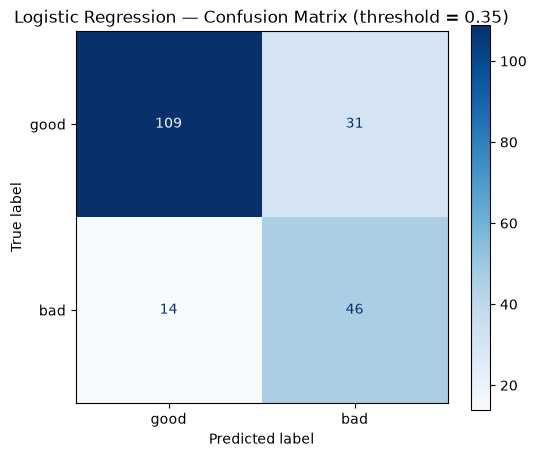

In [90]:
best_threshold = 0.35
y_pred_best = (y_proba >= best_threshold).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_best),
    display_labels=['good', 'bad']
).plot(cmap='Blues', ax=ax)
ax.set_title(f'Logistic Regression — Confusion Matrix (threshold = {best_threshold})')
plt.show()

In [91]:
examples_idx = [
    zone_df[zone_df['zone'] == z].index[0]
    for z in ['Auto-approve', 'Manual review', 'Auto-reject']
]

examples = X_test.iloc[examples_idx][
    ['status_checking', 'credit_history', 'duration_months',
     'credit_amount', 'savings', 'age']
].copy()

examples['probability_bad'] = zone_df.loc[examples_idx, 'probability'].round(3).values
examples['zone'] = zone_df.loc[examples_idx, 'zone'].values
examples['actual'] = zone_df.loc[examples_idx, 'actual'].map({0: 'good', 1: 'bad'}).values

examples

,status_checking,credit_history,duration_months,credit_amount,savings,age,probability_bad,zone,actual
128,A12,A34,12,1860,A61,34,0.101,Auto-approve,good
30,A12,A32,18,1913,A64,36,0.227,Manual review,good
289,A11,A33,24,1024,A61,48,0.619,Auto-reject,bad


 Example Applicants

Applicant 1: Auto-approve (p = 0.101)
The applicant requests a small, short-term loan (1,860 DM for 12 months) and has a modest positive checking balance (0–200 DM). The predicted risk is very low, so the loan is approved automatically; the client indeed turned out to be a good borrower.

Applicant 2: Manual review (p = 0.227)
The applicant has a clean repayment history (existing credits paid back duly) and strong savings (>= 1,000 DM), but the checking balance is low and the loan runs for 18 months. The risk is only slightly above the auto-approve limit, so an analyst should confirm income and employment; in reality this client was good, so a review would most likely lead to approval.

Applicant 3: Auto-reject (p = 0.619)
The applicant has a negative checking account balance (< 0 DM), a history of payment delays, and almost no savings (< 100 DM), while requesting a loan for 24 months. These are strong warning signs, so the application is rejected automatically; the client was in fact a bad borrower.

All three decisions match the actual outcomes, showing that the decision zones separate low-, medium- and high-risk applicants in a way that makes business sense.